In [1]:
import pandas as pd
import openpyxl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from sklearn.impute import KNNImputer
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

#### 1. Descripción inical

In [2]:
df = pd.read_excel('../data/cruda/tesis_21_07_2023_correccion_1.xlsx', engine='openpyxl')
print('Longitud de la base de datos:', df.shape)
print('Atributos:', df.dtypes)
#df.head()

Longitud de la base de datos: (355, 1098)
Atributos: Study ID                                              int64
Sexo                                                 object
edad el dia de la cirugia                             int64
Antecedentes (choice=HTA)                            object
Antecedentes (choice=DL)                             object
                                                  ...      
complicaciones cierre estoma otro                    object
Clavien-Dindo complicación cierre estoma             object
Comments                                             object
fecha de primera consulta en MAP o urg       datetime64[ns]
fecha de primera consulta cirugia            datetime64[ns]
Length: 1098, dtype: object


#### 2. Preprocesamiento

In [3]:
# variables muy poco descripctivas, cambiamos el nombre de las variables. 
list_name_df = df.columns.tolist()
print('Nombre de variables: ', list_name_df)

Nombre de variables:  ['Study ID', 'Sexo', 'edad el dia de la cirugia', 'Antecedentes (choice=HTA)', 'Antecedentes (choice=DL)', 'Antecedentes (choice=DM2)', 'Antecedentes (choice=IAM)', 'Antecedentes (choice=Cardiopatía isquémica)', 'Antecedentes (choice=FA)', 'Antecedentes (choice=EPOC)', 'Antecedentes (choice=Ictus)', 'Antecedentes (choice=vasculopatía)', 'Antecedentes (choice=HBP)', 'Antecedentes (choice=otros)', 'Antecedentes (choice=hipotiroidismo)', 'Antecedentes (choice=sin antecedentes)', 'Antecedentes (choice=colagenopatias)', 'Antecedentes (choice=IRC)', 'variables Charleson  (choice=Demencia)', 'variables Charleson  (choice=Ulc GD)', 'variables Charleson  (choice=Hepatopatia leve)', 'variables Charleson  (choice=DM con daño)', 'variables Charleson  (choice=Hepatopatía severa)', 'variables Charleson  (choice=TVP o TEP)', 'variables Charleson  (choice=depresión)', 'variables Charleson  (choice=VHC)', 'variables Charleson  (choice=VIH)', 'antecedentes otros', 'inmunosupresion'

In [4]:
# modificamos nombre de variable
# Cargamos dict con variables arregladas

lst_new_names = []
with open(r'..\data\cruda\dict_names_changes.txt', 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        lst_new_names.append(line)


df.columns = lst_new_names
print('Atributos:', df.dtypes)
#df.head()

Atributos: ID_Paciente                                          int64
Sexo                                                object
Edad_Cirugia                                         int64
Hta                                                 object
Dl                                                  object
                                                 ...      
Complicaciones_Cierre_Estoma_Otros                  object
Clavien_Dindo_complicacion_cierre_estoma            object
Comentarios_Generales                               object
Fecha_Primera_Consulta_MAP                  datetime64[ns]
Fecha_Primera_Consulta_Cirugia              datetime64[ns]
Length: 1098, dtype: object


In [5]:
# Creamos columna ratio ganglio por interés clínico 
# ratio_ganglios=nº ganglios positivos/nº total ganglios
# Cambiamos si / no, por 1 y 0.
# Hombre 0, mujer 1

df['Ratio_ganglios'] = np.where(
        df['Ganglios_Totales'] > 0,
        (df["Ganglios_Positivos"] / df["Ganglios_Totales"]).round(6), 
        np.nan  # evita división por 0
)

df = df.replace({"no": 0, "si": 1, "No": 0, "Si": 1, "NO": 0, "SI": 1})
df['Sexo'] = df['Sexo'].replace({'hombre': 0, 'mujer': 1, 'Hombre': 0, 'Mujer':1 })

df['Anastomosis_Realizada'] = df['Anastomosis_Realizada'].replace({0: 'No'})
# dejamos Anastomosis como cadena de Texto

#Modificamos clasififcación ASA 
inf_cla_asa = {"I": 1, "II": 2, "III": 3, "IV": 4}

#Modificamos estado fumador
inf_fum = dict_fuma = {"no fuma":0, "exfumador":1, "si activo":2}

df["Clasificacion_ASA"] = (df["Clasificacion_ASA"].astype("string").str.strip().str.upper().map(inf_cla_asa).astype("Int64"))
df['Estado_Fumador'] = (df['Estado_Fumador'].astype('string').str.strip().str.lower().map(inf_fum).astype('Int64'))
df[["Sexo", "Estado_Fumador", "Clasificacion_ASA", 'Anastomosis_Realizada']].head()

,Sexo,Estado_Fumador,Clasificacion_ASA,Anastomosis_Realizada
0,0,1,3,No
1,1,0,3,TL mecánica
2,1,0,2,TT mecánica
3,1,0,3,LL manual
4,1,0,2,TT mecánica


#### 3. SELECCIÓN DE VARIABLE 

In [6]:
# Mediante validez clínica

# Sociodemográficas / estado basal del paciente
col_sociodemograficas = [
    "ID_Paciente",
    "Sexo",
    "Edad_Cirugia",
    "IMC",
    "Estado_Fumador",
    "Dependencia_Funcional",
    "Clasificacion_ASA",
]

# Antecedentes relevantes
col_antecendentes = [   
    "Dm2",
    "Hta",
    "Dl",
    "Cardiopatia_Isquemica",
    "Epoc",
    "Irc",
    #"Vih",
    "Inmunosupresion"
]

# Tumor / anatomía patológica 
col_tumor = [
    # Localización
    "Localizacion_ascendente",
    "Localizacion_sigma",
    "Localizacion_recto",

    # Estadiaje patológico
    "Estadio_T_Patologico",
    "estadio_N",
    "Estadio_M",

    # Carga ganglionar
    "Ratio_ganglios",

    # Factores pronóstico quirúrgico-patológicos
    "Invasion_Vascular",
    "Grado_Reseccion_R",
]

# Tratamiento 
col_tratamiento = [
    "Neoadyuvancia",
    "Abordaje_Quirurgico",
    "Tipo_Intervencion",
    "Anastomosis_Realizada",
    "Estoma_Realizado",
    "Quimioterapia_Adyuvante_si",
    "Finalizacion_Prematura_QT_si",
    "Toxicidad_QT_si"
]

tipo_intervencion = [
    # Tipo de intervencion
    'Tipo_Intervencion_hemicolectomia_derecha',
    'Tipo_Intervencion_hemicolectomia_derecha_ampliada',
    'Tipo_Intervencion_hemicolectomia_izquierda',
    'Tipo_Intervencion_sigmoidectomia',
    'Tipo_Intervencion_reseccion_anterior',
    'Tipo_Intervencion_reseccion_anterior_baja',
    'Tipo_Intervencion_reseccion_anterior_ultrabaja',
    'Tipo_Intervencion_colectomia_subtotal',
    'Tipo_Intervencion_colectomia_total',
    'Tipo_Intervencion_reseccion_segmentaria',
    'Tipo_Intervencion_amputacion_abdominoperineal',
]

col_outcomes = [
    # Complicación global y principales “hard endpoints”
    "Complicaciones_Ingreso_si",
    "Complicacion_fuga_anastomotica",
    "Complicacion_infeccion_sitio_quirurgico",
    "Complicacion_neumonia",
    "Complicacion_TEP",   
    'Complicacion_ileo_paralitico',
    'Complicacion_insuficiencia_renal',
    "Reintervencion_si",
    "Reingreso_30d_si",
    "Fecha_Primera_Consulta_Cirugia",
    "Fecha_Ingreso_Cirugia",
    "Fecha_Alta_Hospitalaria",
]

# Supervivencia / seguimiento 
col_supervivencia = [
    "Recidiva_si",
    "exitus",
    "Fecha_Exitus",
    "Fecha_Ultima_Visita",
    "Fecha_Diagnostico_Recidiva"
]

new_cols = (
    col_sociodemograficas
    + col_antecendentes
    + col_tumor
    + col_tratamiento
    + tipo_intervencion
    + col_outcomes
    + col_supervivencia
)

df_post = df.loc[:, new_cols]
print('Preprocesado: ', df_post.shape)
print('Antes: ', df.shape)

Preprocesado:  (355, 59)
Antes:  (355, 1099)


In [7]:
# Formato fechas 
cols_dates = [
    "Fecha_Ingreso_Cirugia",
    "Fecha_Alta_Hospitalaria",
    "Fecha_Exitus",
    "Fecha_Ultima_Visita",
    "Fecha_Diagnostico_Recidiva",
    "Fecha_Primera_Consulta_Cirugia"
]

for i in cols_dates:
    df_post[i] = pd.to_datetime(df_post[i], errors="coerce")

df_post.rename(columns={"estadio_N": "Estadio_N"}, inplace=True)

In [8]:
# Creación de variables de interés
# Revisamos los NANs de variables que necesitamos

val_out = ['Fecha_Ingreso_Cirugia', 'Fecha_Alta_Hospitalaria', 'Fecha_Diagnostico_Recidiva', 'Recidiva_si', 'Fecha_Ultima_Visita', 'Fecha_Exitus']
print('Nans en variables de interés')
display(df_post[val_out].isna().sum())

# Imputamos con una bbdd mini proporcionada

df_mini = pd.read_excel(r'..\data\cruda\base tesis mini.xlsx', engine='openpyxl')
df_mini['exitus'] = df_mini['exitus'].str.lower().replace({'si': 1, 'no': 0})
df_mini['recidiva'] = df_mini['recidiva'].str.lower().replace({'si': 1, 'no': 0})


map_cols = {
    'Fecha_Alta_Hospitalaria':        'Fecha alta',
    'Fecha_Ingreso_Cirugia':          'fecha de cirugia',
    'Fecha_Diagnostico_Recidiva':     'fecha de dg de recidiva',
    'Fecha_Exitus':                   'fecha exitus',
    'Fecha_Ultima_Visita':            'ultima visita',
    'exitus':                         'exitus',
    'Recidiva_si':                    'recidiva'  
}

map_id = df_mini.drop_duplicates(subset='Study ID').set_index('Study ID')

for col_post, col_mini in map_cols.items():
    if col_mini in map_id.columns:
        
        df_post[col_post] = (
            df_post['ID_Paciente']
            .map(map_id[col_mini])
            .combine_first(df_post[col_post])
        )

Nans en variables de interés


Fecha_Ingreso_Cirugia           8
Fecha_Alta_Hospitalaria         0
Fecha_Diagnostico_Recidiva    283
Recidiva_si                     0
Fecha_Ultima_Visita            33
Fecha_Exitus                  194
dtype: int64

In [9]:
# Creación de nuevas variables
df_post["Estancia_Dias"] = (df_post["Fecha_Alta_Hospitalaria"] - df_post["Fecha_Ingreso_Cirugia"]).dt.days # Estancia hospitalaria (días)

fin_supervivencia = df_post["Fecha_Exitus"].fillna(df_post["Fecha_Ultima_Visita"]) # Superviviencia
df_post["Supervivencia_Dias"] = (fin_supervivencia - df_post["Fecha_Ingreso_Cirugia"]).dt.days 

fin_libre_recidiva = df_post["Fecha_Diagnostico_Recidiva"].fillna(df_post["Fecha_Ultima_Visita"]) # Recidiva (aparición cáncer)
mask_no_recidiva = df_post['Recidiva_si'].eq(0) # Si no hay recidiva, días totales sin recidiva = hasta muerte

fin_libre_recidiva = fin_libre_recidiva.where(
    ~(mask_no_recidiva & fin_libre_recidiva.isna()),
    df_post["Fecha_Exitus"]
)

df_post["Libre_Recidiva_Dias"] = (fin_libre_recidiva - df_post["Fecha_Ingreso_Cirugia"]).dt.days

# Evitar duraciones negativas
for c in ["Estancia_Dias", "Supervivencia_Dias"]:
    df_post.loc[df_post[c] < 0, c] = pd.NA

In [10]:
# Inconsistencias

mask_alta_ingre = df_post["Fecha_Alta_Hospitalaria"] < df_post["Fecha_Ingreso_Cirugia"]
mask_1_sin_fecha = df_post["exitus"].eq(1) & df_post["Fecha_Exitus"].isna()
mask_0_con_fecha = df_post["exitus"].eq(0) & df_post["Fecha_Exitus"].notna()

mask_exitus_antes_ingreso = df_post["Fecha_Exitus"] < df_post["Fecha_Ingreso_Cirugia"]
mask_ult_visita_antes_ingreso = df_post["Fecha_Ultima_Visita"] < df_post["Fecha_Ingreso_Cirugia"]
mask_recidiva_antes_ingreso = df_post["Fecha_Diagnostico_Recidiva"] < df_post["Fecha_Ingreso_Cirugia"]

mask_1_sin_fecha_rec = df_post["Recidiva_si"].eq(1) & df_post["Fecha_Diagnostico_Recidiva"].isna()
mask_0_con_fecha_rec = df_post["Recidiva_si"].eq(0) & df_post["Fecha_Diagnostico_Recidiva"].notna()

print("Filas con Recidiva_si=1 y Fecha_Diagnostico_Recidiva ausente:", mask_1_sin_fecha_rec.sum())
print("Filas con Recidiva_si=0 y Fecha_Diagnostico_Recidiva presente:", mask_0_con_fecha_rec.sum())

print("Filas con Exitus < Fecha_Ingreso_Cirugia:", mask_exitus_antes_ingreso.sum())
print("Filas con Ultima_Visita < Fecha_Ingreso_Cirugia:", mask_ult_visita_antes_ingreso.sum())
print("Filas con Diagnostico_Recidiva < Fecha_Ingreso_Cirugia:", mask_recidiva_antes_ingreso.sum())


print('Filas con inconsistencia Alta < Ingreso: ', mask_alta_ingre.sum())
print("Filas con exitus=1 y Fecha_Exitus ausente:", mask_1_sin_fecha.sum())
print("Filas con exitus=0 y Fecha_Exitus presente:", mask_0_con_fecha.sum())

df_post.rename(columns={'exitus': 'Exitus'}, inplace=True)

mask_total = (
    mask_exitus_antes_ingreso
    | mask_ult_visita_antes_ingreso
    | mask_recidiva_antes_ingreso
    | mask_alta_ingre
    | mask_1_sin_fecha
    | mask_0_con_fecha
    | mask_1_sin_fecha_rec
    | mask_0_con_fecha_rec
)

#display(df_post.loc[mask_total,
#    ["ID_Paciente","Fecha_Ingreso_Cirugia",'Fecha_Alta_Hospitalaria', "Fecha_Exitus","Fecha_Diagnostico_Recidiva", 
#     'Recidiva_si', "Fecha_Ultima_Visita", 'Exitus']
#].head(20))

print('Filas totales: ', mask_total.sum())

# Estrategia, no borramos filas sesgadas por fechas porque no generaremos datos sintéticos con fechas, creamos intervalos.
# Se presupone que ha habido mala práctica en la toma de datos. 


Filas con Recidiva_si=1 y Fecha_Diagnostico_Recidiva ausente: 3
Filas con Recidiva_si=0 y Fecha_Diagnostico_Recidiva presente: 1
Filas con Exitus < Fecha_Ingreso_Cirugia: 0
Filas con Ultima_Visita < Fecha_Ingreso_Cirugia: 0
Filas con Diagnostico_Recidiva < Fecha_Ingreso_Cirugia: 0
Filas con inconsistencia Alta < Ingreso:  0
Filas con exitus=1 y Fecha_Exitus ausente: 0
Filas con exitus=0 y Fecha_Exitus presente: 0
Filas totales:  4


In [11]:
# Para Exitus y recidiva imputamos según lógica clínica 

exitus_num = pd.to_numeric(df_post["Exitus"], errors="coerce")
recidiva_num = pd.to_numeric(df_post["Recidiva_si"], errors="coerce")

mask_fecha_exitus = df_post["Fecha_Exitus"].notna()
mask_fecha_recidiva = df_post["Fecha_Diagnostico_Recidiva"].notna()

df_post['Exitus_def'] = exitus_num.copy()
df_post.loc[mask_fecha_exitus, 'Exitus_def'] = 1 # Si tienen fecha Exitus, Exitus 1
df_post.loc[exitus_num.eq(1) & ~mask_fecha_exitus, "Exitus_def"] = 1 # Tiene exitus, pero no fecha, lógica clínica
df_post.loc[exitus_num.isna() & ~mask_fecha_exitus, "Exitus_def"] = pd.NA # Ni fecha, ni exitus
df_post["Exitus_def"] = df_post["Exitus_def"].astype("Int64")


df_post["Recidiva_def"] = recidiva_num
df_post.loc[mask_fecha_recidiva, "Recidiva_def"] = 1
df_post.loc[recidiva_num.eq(1) & ~mask_fecha_recidiva, "Recidiva_def"] = 1 # Falta la fecha, pero lo más coherentes es imputar 1, Existe Recidiva
df_post.loc[recidiva_num.isna() & ~mask_fecha_recidiva, "Recidiva_def"] = pd.NA
df_post["Recidiva_def"] = df_post["Recidiva_def"].astype("Int64")

In [12]:
df_post = df_post.drop(columns=["Exitus", "Recidiva_si"])
# Sin fechas
df_no_dates = df_post.drop(columns=cols_dates)

In [13]:
df = df_no_dates.copy()

In [14]:
# Formatos 

col_change_for_str_to_num = ['IMC']

col_str_to_int = ['Estado_Fumador', 'Clasificacion_ASA','Inmunosupresion',"Hta", 'Dl',  
                  'Invasion_Vascular', 'Neoadyuvancia', 'Estoma_Realizado', 
                  'Exitus_def', 'Recidiva_def', 'Estancia_Dias', 'Supervivencia_Dias', 'Libre_Recidiva_Dias' ]

for i in col_change_for_str_to_num:
    s = df[i].astype(str).str.strip().str.replace(",", ".", regex=False)
    s = s.replace(["", "NA", "N/A", "nan"], pd.NA)
    df[i] = pd.to_numeric(s, errors="coerce").astype("float64")

for r in col_str_to_int:
    s = df[r].astype(str).str.strip().str.replace(",", ".", regex=False)
    s = s.replace(["", "NA", "N/A", "nan"], pd.NA)
    df[r] = pd.to_numeric(s, errors="coerce").astype("Int64")

In [15]:
# Imputamos Estadio T con mini base de datos.
map_cols_t = {
    'Estadio_T_Patologico':      'estadio T'
}

map_id_t = df_mini.drop_duplicates(subset='Study ID').set_index('Study ID')

for col_post, col_mini in map_cols_t.items():
    if col_mini in map_id_t.columns:
        
        df[col_post] = (
            df['ID_Paciente']
            .map(map_id_t[col_mini])
            .combine_first(df[col_post]))


#imputamos Estadio Global TNM y Estadio T con mini base de datos.
df["Estadio_Global_TNM"] = None

t = df["Estadio_T_Patologico"].fillna("MISSING")
n = df["Estadio_N"].fillna("MISSING")
m = df["Estadio_M"].fillna("MISSING")

condiciones = [
    m.eq("M1"),                                           # IV
    m.eq("M0") & n.isin(["N1", "N2"]),                    # III
    m.eq("M0") & n.eq("N0") & t.isin(["T3", "T4"]),        # II
    m.eq("M0") & n.eq("N0") & t.isin(["T1", "T2"]),        # I
]

valores_tnm = ["IV", "III", "II", "I"]

df["Estadio_Global_TNM"] = np.select(condiciones, valores_tnm, default=pd.NA)
df["Estadio_Global_TNM"] = df["Estadio_Global_TNM"].astype("string")
df[["Estadio_T_Patologico", 'Estadio_N', "Estadio_M", "Estadio_Global_TNM"]].head()

,Estadio_T_Patologico,Estadio_N,Estadio_M,Estadio_Global_TNM
0,T1,N0,M0,I
1,T4a,N2b,NaN,<NA>
2,T3,N0,NaN,<NA>
3,T3,N0,NaN,<NA>
4,T3,N0,M0,II


In [16]:
map_cols_est = {
    'Estadio_Global_TNM':        'Estadio_Cancer'
}

map_id_est = df_mini.drop_duplicates(subset='Study ID').set_index('Study ID')

for col_post, col_mini in map_cols_est.items():
    if col_mini in map_id_est.columns:
        
        df[col_post] = (
            df['ID_Paciente']
            .map(map_id_est[col_mini])
            .combine_first(df[col_post]))

df["Estadio_Global_TNM"] = df["Estadio_Global_TNM"].replace({None: np.nan})


# Si hay x en M y estadio global = IV es M1
mask_m_x = df["Estadio_M"].astype("string").str.contains("x", case=False, na=True)
mask_estadio_iv = df["Estadio_Global_TNM"].astype("string").str.contains("IV", case=False, na=False)

df.loc[mask_m_x & mask_estadio_iv, "Estadio_M"] = "M1"

# Si hay x en M y estadio global = I - III es M0
mask_estadio_i_iii = df["Estadio_Global_TNM"].astype("string").str.match(r"^(I|II|III)", case=False, na=False)
df.loc[mask_m_x & mask_estadio_i_iii, "Estadio_M"] = "M0"

# N x = N0
mask_nx = df["Estadio_N"].astype("string") == "x"
df.loc[mask_nx, "Estadio_N"] = 'N0'

# T == "x" poner estadio global = 0
mask_tx = df["Estadio_T_Patologico"].astype("string") == "x"
df.loc[mask_tx, "Estadio_Global_TNM"] = '0'
df.loc[mask_tx, "Estadio_T_Patologico"] = 'T0'

# Validación clínica de oncóloga
df.loc[df["ID_Paciente"] == 64, "Estadio_M"] = "M0"
df.loc[df["ID_Paciente"] == 64, "Estadio_Global_TNM"] = "I"

df = df[df["ID_Paciente"] != 66]

In [17]:
cols = ["Estadio_T_Patologico", "Estadio_N", "Estadio_M", 'Estadio_Global_TNM']

mask_x = df[cols].astype(str).apply(lambda col: col.str.contains("x", case=False, na=False)).any(axis=1)
mask_nan = df[cols].isna().any(axis=1)

mask = mask_x | mask_nan

df["Estadio_M"] = df["Estadio_M"].replace({"x": np.nan, "X": np.nan})

In [18]:
df["Localizacion"] = None

map_cols_loc = {
    'Localizacion':        'localizacion'
}

map_id_loc = df_mini.drop_duplicates(subset='Study ID').set_index('Study ID')

for col_post, col_mini in map_cols_loc.items():
    if col_mini in map_id_loc.columns:
        
        df[col_post] = (
            df['ID_Paciente']
            .map(map_id_loc[col_mini])
            .combine_first(df[col_post]))
        
# Indicaciones oncóloga
df["Localizacion"] = df["Localizacion"].replace({None:'recto'})

# Los valores NAN de Neoadyuvacnia = no aplica
# Creamos otra variable = 2, significado, no aplica
df["Neoadyuvancia"] = df["Neoadyuvancia"].fillna(2)

In [19]:
cols_str = [
    "Grado_Reseccion_R",
    "Estadio_T_Patologico",
    "Anastomosis_Realizada",
    "Tipo_Intervencion",
    "Abordaje_Quirurgico",
    "Estadio_M",
    "Estadio_N",
    'Estadio_Global_TNM',
    'Localizacion'
]

df[cols_str] = df[cols_str].astype("string")

In [20]:
# Sentido clínico
mask_inmunosuprimido = (
    df["Neoadyuvancia"].eq(1) |
    df["Quimioterapia_Adyuvante_si"].eq(1)
)

df["Inmunosupresion"] = df["Inmunosupresion"].copy()

# Los NA se imputan según reglas
df.loc[df["Inmunosupresion"].isna() & mask_inmunosuprimido, "Inmunosupresion"] = 1
df.loc[df["Inmunosupresion"].isna() & ~mask_inmunosuprimido, "Inmunosupresion"] = 0

In [21]:
# Cambio en columna tipo de procedimiento

mapeo_procedimiento = {
    'Tipo_Intervencion_hemicolectomia_derecha': 'HCD',
    'Tipo_Intervencion_hemicolectomia_derecha_ampliada': 'HCDA',
    'Tipo_Intervencion_hemicolectomia_izquierda': 'HCI',
    'Tipo_Intervencion_sigmoidectomia': 'Sigma',
    'Tipo_Intervencion_reseccion_anterior': 'RA',
    'Tipo_Intervencion_reseccion_anterior_baja': 'RAB',
    'Tipo_Intervencion_reseccion_anterior_ultrabaja': 'RAUB',
    'Tipo_Intervencion_colectomia_subtotal': 'CST',
    'Tipo_Intervencion_colectomia_total': 'CT',
    'Tipo_Intervencion_reseccion_segmentaria': 'ResSeg',
    'Tipo_Intervencion_amputacion_abdominoperineal': 'AAP',
}

# Crear la nueva columna recorriendo el mapeo
df['Tipo_Procedimiento'] = None
for col, abrev in mapeo_procedimiento.items():
    mask = df[col] == 1
    df.loc[mask, 'Tipo_Procedimiento'] = abrev

# Eliminar las 11 columnas originales
df.drop(columns=list(mapeo_procedimiento.keys()), inplace=True)

correccion_procedimiento = {
    29:  'RA',
    39:  'ResSeg',
    65:  'RAB',
    82:  'CT',
    98:  'RA',
    109: 'RA',
    197: 'Sigma',
    198: 'Sigma',
    220: 'ResMultiple',
    268: 'ResSeg',
    309: 'RAB',
}

for id_pac, proc in correccion_procedimiento.items():
    df.loc[df['ID_Paciente'] == id_pac, 'Tipo_Procedimiento'] = proc

df = df[df['ID_Paciente'] != 220].reset_index(drop=True) # No tiene representatitvidad 
df['Tipo_Procedimiento'] = df['Tipo_Procedimiento'].fillna('ResLoc')
df['Tipo_Procedimiento'] = df['Tipo_Procedimiento'].astype('string')

In [22]:
#df

#### 4. MÉTRICAS DESCRIPTIVAS

In [23]:
#descriptivo de las variables, tipo, porcejntaje de missings, rangos, etc
column_names = df.columns
summary = pd.DataFrame({
    "Variable": column_names,
    "Type": [df[col].dtype for col in column_names],
    "Missing_Percentage": [(df[col].isnull().sum() / len(df)).round(4) * 100 for col in column_names]
})

# Display the summary
summary = summary.sort_values('Missing_Percentage', ascending=False)
#summary

In [24]:
real_num_cols = ['Edad_Cirugia', 'IMC', 'Ratio_ganglios', 'Estancia_Dias', 'Supervivencia_Dias', 'Libre_Recidiva_Dias']

cat_cols = ["Sexo",
    "Estado_Fumador",
    "Dependencia_Funcional",
    "Clasificacion_ASA",
    "Dm2",
    "Hta",
    "Dl",
    "Cardiopatia_Isquemica",
    "Epoc",
    "Irc",
    "Inmunosupresion",
    "Localizacion_ascendente",
    "Localizacion_sigma",
    "Localizacion_recto",
    'Localizacion',
    "Invasion_Vascular",
    "Neoadyuvancia",
    "Estoma_Realizado",
    "Quimioterapia_Adyuvante_si",
    "Finalizacion_Prematura_QT_si",
    "Toxicidad_QT_si",
    "Complicaciones_Ingreso_si",
    "Complicacion_fuga_anastomotica",
    "Complicacion_infeccion_sitio_quirurgico",
    "Complicacion_neumonia",
    "Complicacion_TEP",
    'Complicacion_ileo_paralitico', 
    'Complicacion_insuficiencia_renal',
    "Reintervencion_si",
    "Reingreso_30d_si",
    "Exitus_def",
    "Recidiva_def",
    
    # texto
    "Grado_Reseccion_R",
    "Estadio_T_Patologico",
    "Anastomosis_Realizada",
    "Tipo_Intervencion",
    'Tipo_Procedimiento',
    "Abordaje_Quirurgico",
    "Estadio_M",
    "Estadio_N",
    'Estadio_Global_TNM'
]

In [25]:
# Haya muchas variables categórica que tienen muy poca respresentación de valores positivos, eliminamos
# Muchos NAN, eliminamos
cols_drop = ['Dependencia_Funcional', 'Localizacion_sigma', 'Localizacion_ascendente', 'Localizacion_recto', 'Complicacion_TEP', 'Invasion_Vascular']
df = df.drop(columns=cols_drop)

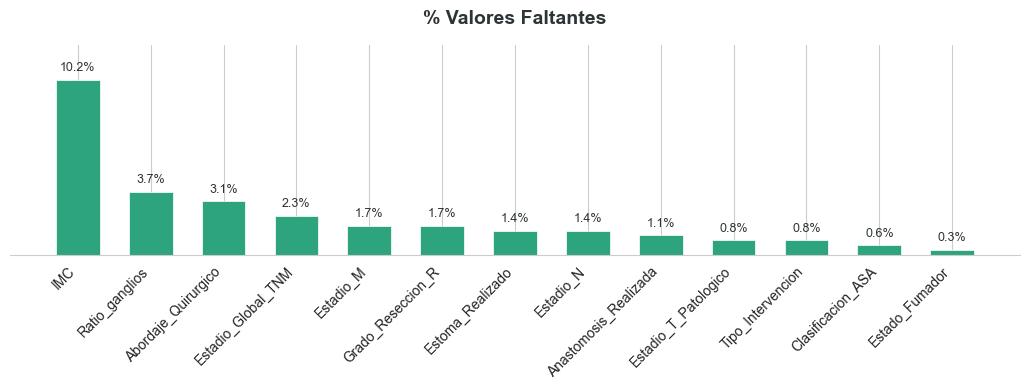

In [26]:
nan_pct = df.isna().mean() * 100
nan_pct = nan_pct[nan_pct > 0].sort_values(ascending=False)

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(max(len(nan_pct) * 0.8, 6), 4))
bars = ax.bar(nan_pct.index, nan_pct, color="#2da47d", width=0.6, edgecolor="white", linewidth=0.5)

for bar, v in zip(bars, nan_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9, color="#2d3436")

ax.set_title("% Valores Faltantes", fontsize=14, fontweight="bold", color="#2d3436", pad=15)
ax.set_ylim(0, nan_pct.max() * 1.2)
ax.yaxis.set_visible(False)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

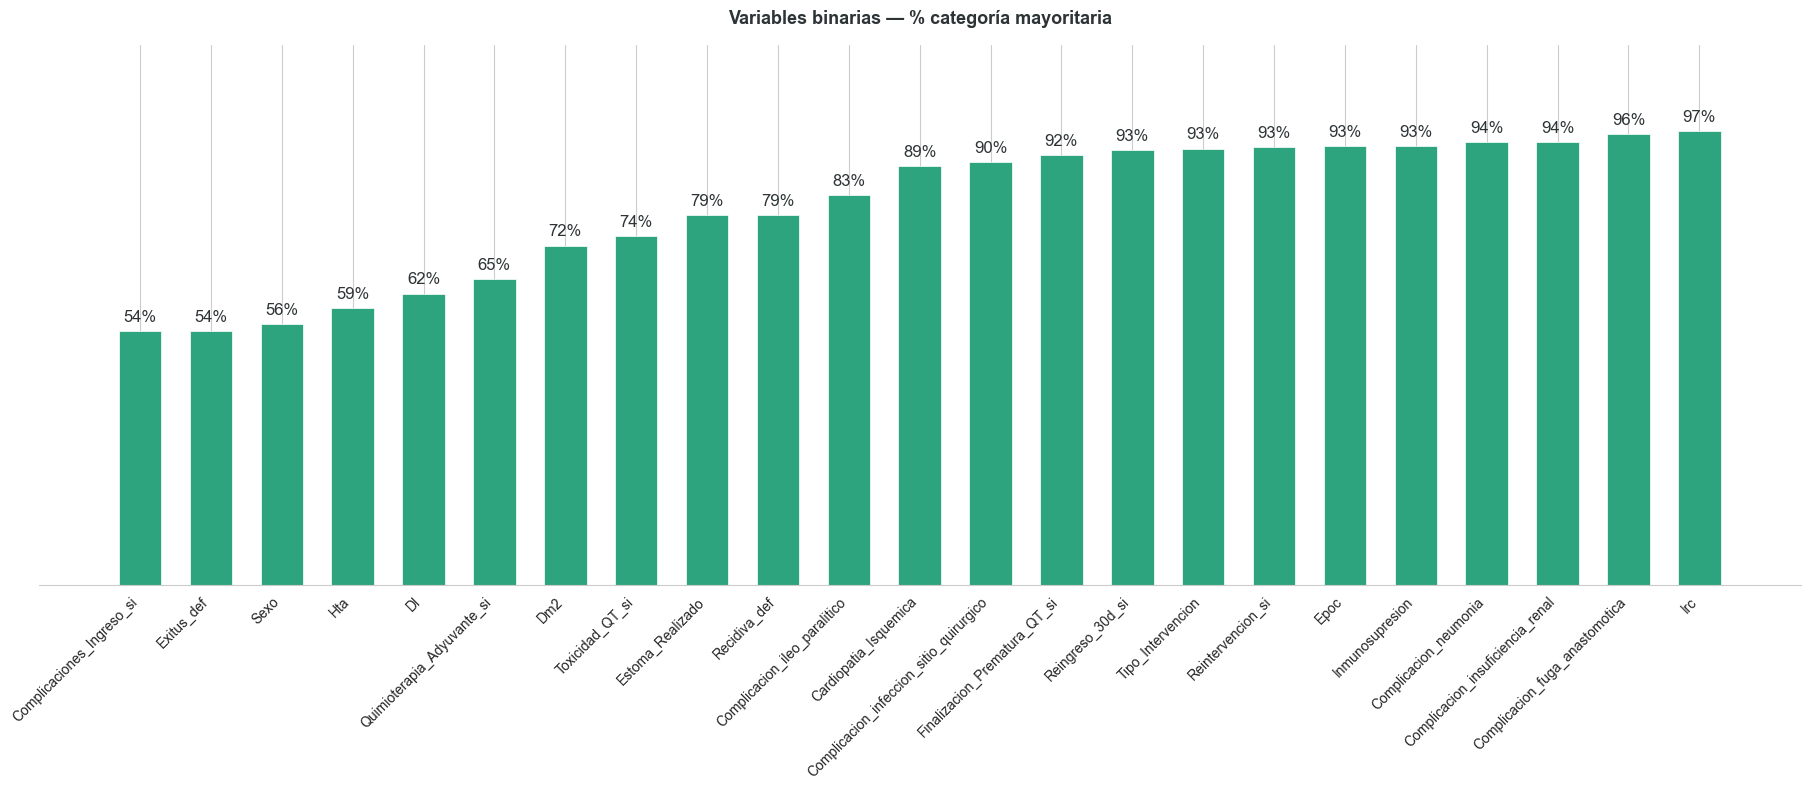

In [27]:
# Binarias: un solo gráfico resumen  
# Separar binarias vs multi-categoría
bin_cols = [c for c in cat_cols if c in df.columns and df[c].nunique() == 2]
multi_cols = [c for c in cat_cols if c in df.columns and df[c].nunique() > 2]

pcts = df[bin_cols].apply(lambda x: x.value_counts(normalize=True).iloc[0]).sort_values()

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(max(len(pcts) * 0.8, 6), 8))
bars = ax.bar(pcts.index, pcts, color="#2da47d", width=0.6, edgecolor="white", linewidth=0.5)

for bar, v in zip(bars, pcts):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", fontsize=12, color="#2d3436")

ax.set_title("Variables binarias — % categoría mayoritaria", fontsize=13, fontweight="bold", color="#2d3436", pad=15)
ax.set_ylim(0, 1.15)
ax.yaxis.set_visible(False)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

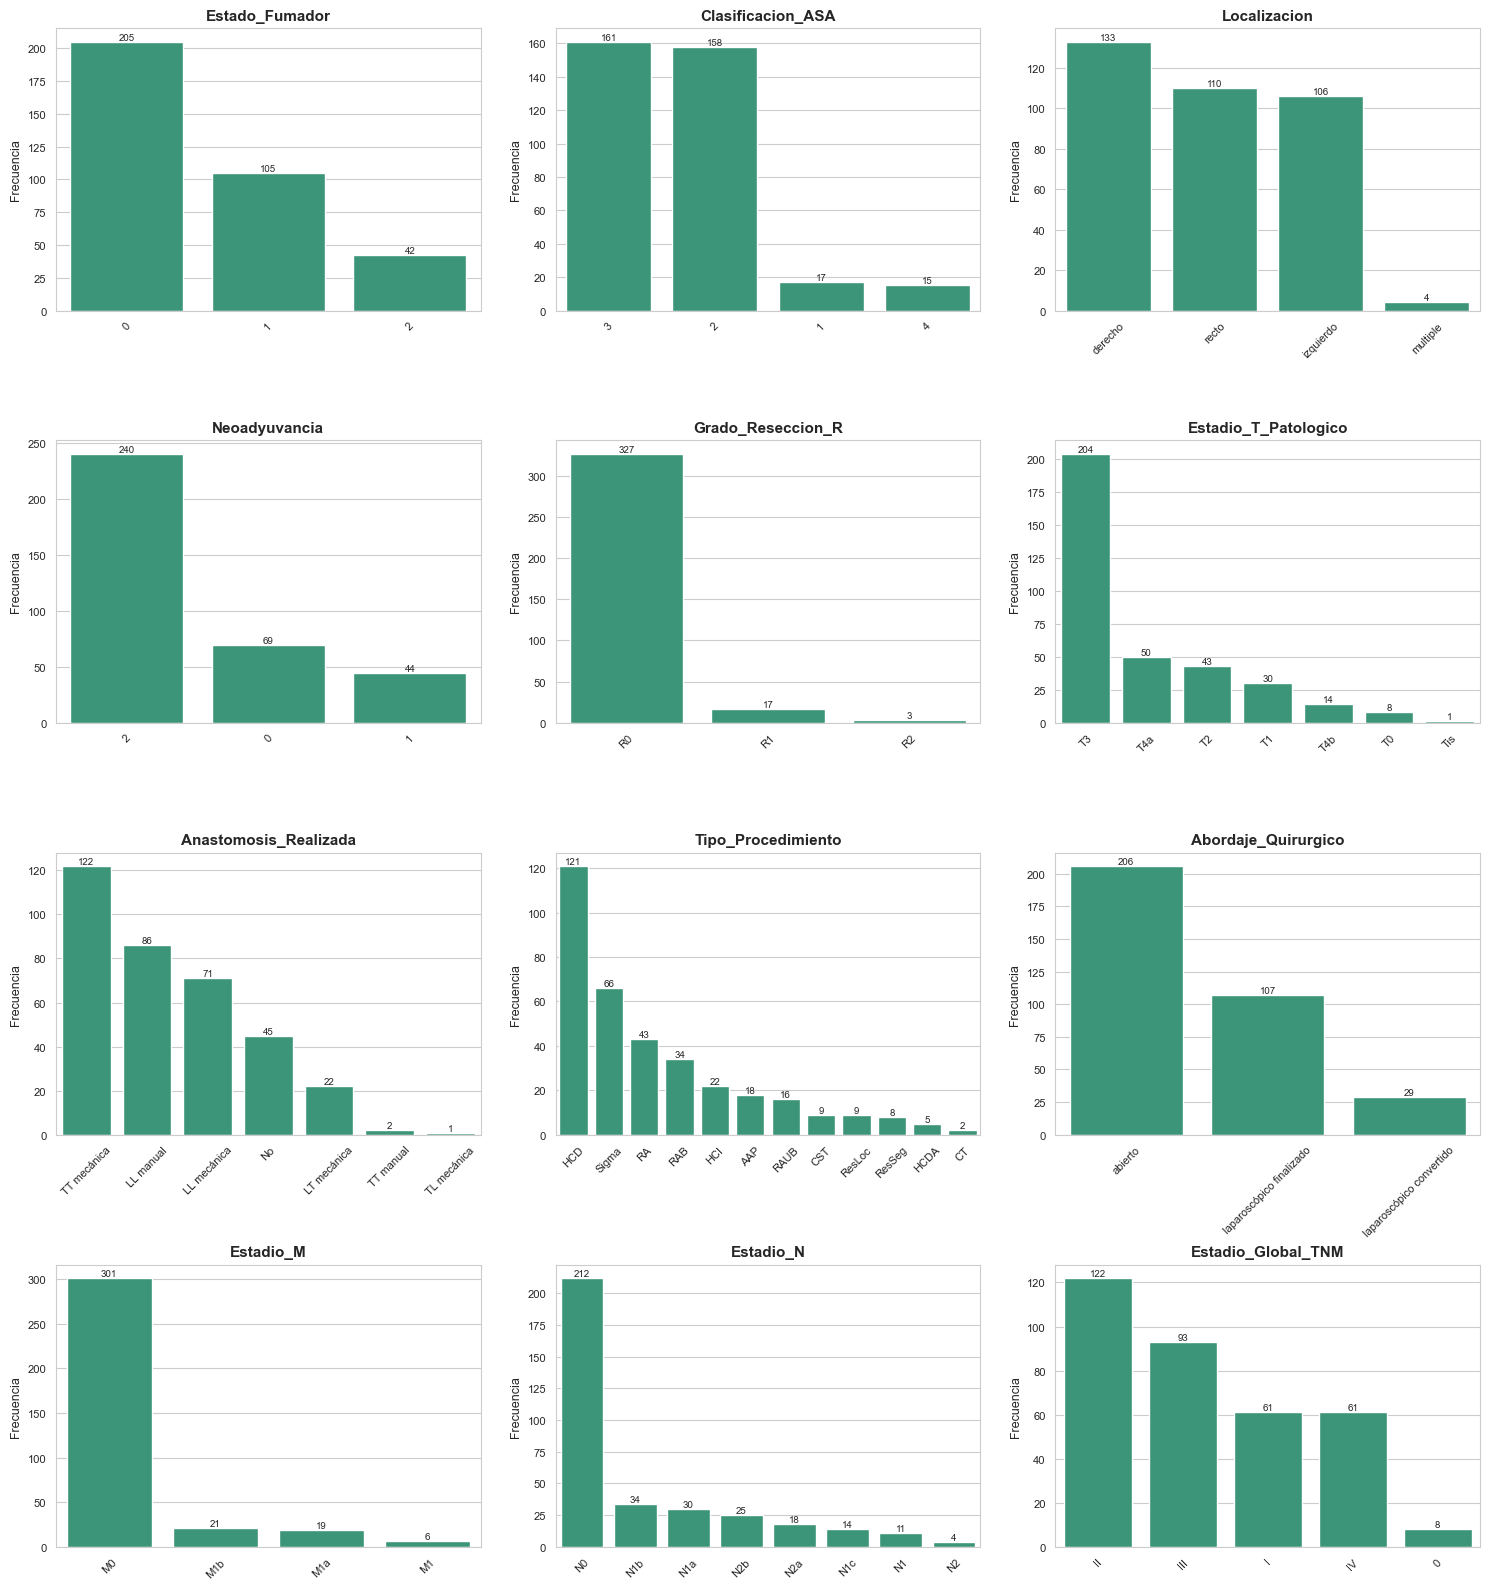

In [28]:
# Multi-categoría: solo estas en grid
ncols = 3
nrows = math.ceil(len(multi_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.ravel()

for i, c in enumerate(multi_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, ax=axes[i], order=order, color="#2da47d")
    axes[i].set_title(c, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia', fontsize=9)
    axes[i].tick_params(axis='x', rotation=45, labelsize=8)
    axes[i].tick_params(axis='y', labelsize=8)
    # Etiquetas con el conteo encima de cada barra
    for p in axes[i].patches:
        axes[i].annotate(f'{int(p.get_height())}',
                         (p.get_x() + p.get_width() / 2, p.get_height()),
                         ha='center', va='bottom', fontsize=7)

for ax in axes[len(multi_cols):]:
    ax.remove()

plt.tight_layout(h_pad=0.5, w_pad=2)
plt.show()

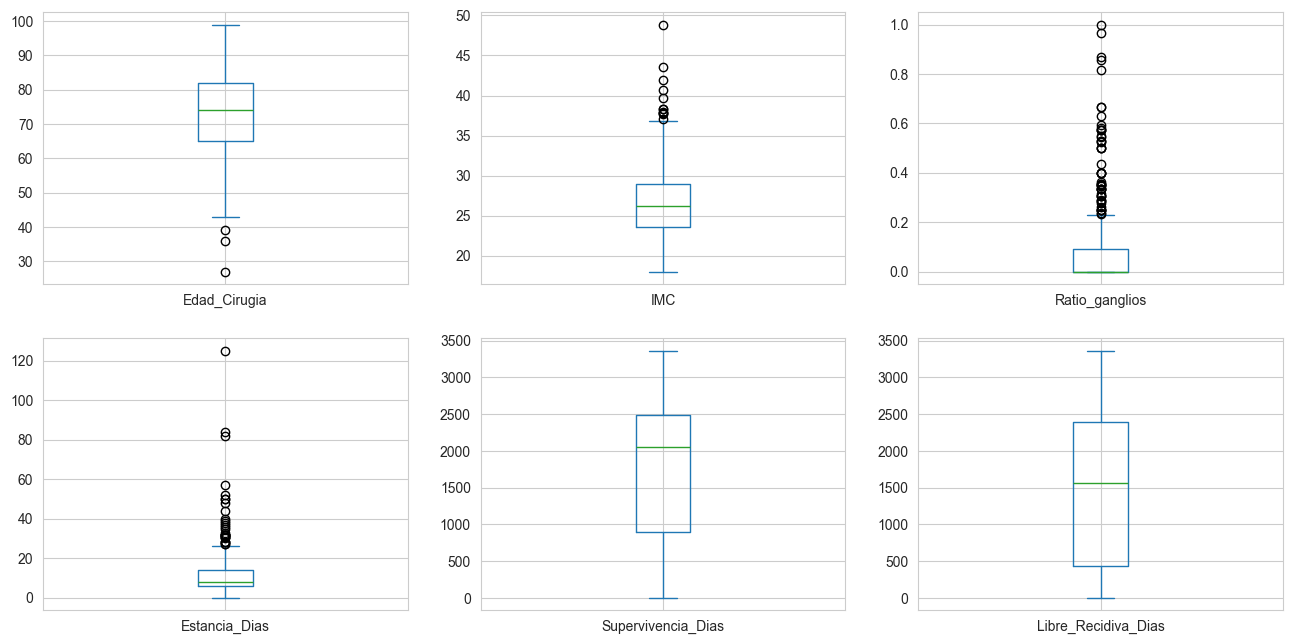

In [29]:
# Box plot variables numéricas
df[real_num_cols].plot(kind='box',subplots=True, layout=(len(real_num_cols)//3 + 1, 3), sharex=False, sharey=False, 
                  figsize=(16, 4*(len(real_num_cols)//3 + 1)))
plt.show()
# Con el objetivo de reflejar la realidad, no quitamos outliers

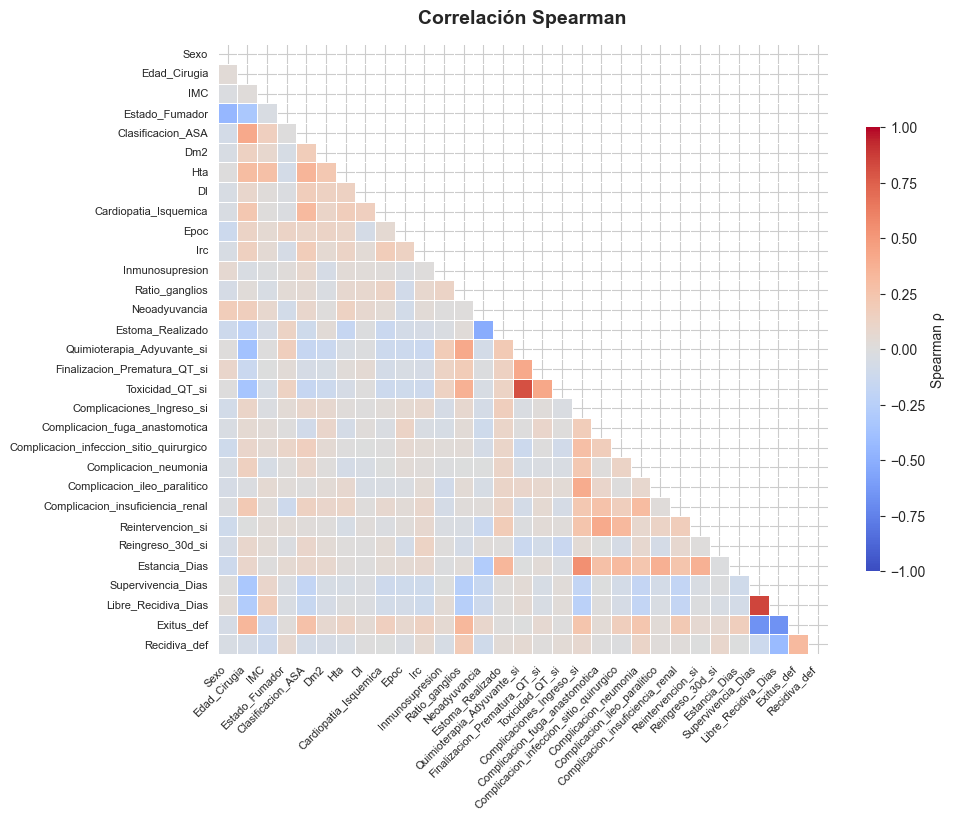

In [30]:
cols_str = [
    # texto
    "Grado_Reseccion_R",
    "Estadio_T_Patologico",
    "Anastomosis_Realizada",
    "Tipo_Intervencion",
    'Tipo_Procedimiento',
    "Abordaje_Quirurgico",
    "Estadio_M",
    "Estadio_N",
    'Estadio_Global_TNM'
]
df2 = df.drop(columns=["ID_Paciente", "Localizacion"] + cols_str, errors="ignore")
corr = df2.corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))  # solo triángulo inferior, la mitad superior es espejo

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True, ax=ax,
            cbar_kws={"shrink": 0.5, "aspect": 30, "label": "Spearman ρ"})
ax.set_title("Correlación Spearman", fontsize=14, fontweight="bold", pad=15)
plt.xticks(fontsize=8, rotation=45, ha="right")
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()
# Algunas columnasn tienen una correlacón alta, lo esperado, pero interés clínico necesario, se mantienen. 

#### 5. ESTRATEGIA MISSINGS

In [31]:
# Estrategia missings
# Imputamos IMC, variable numérica 
# Correlación de todas las numéricas con IMC

num_cols = df.drop(columns=["ID_Paciente"]).select_dtypes(include=["number"]).columns # column numéricas
corr_imc = df[num_cols].corr("spearman")["IMC"].drop("IMC").sort_values(key=abs, ascending=False)

In [32]:
predictoras_imc = [
    'Edad_Cirugia',       # numérica 
    'Clasificacion_ASA',  # ordinal  
    'Hta',                # binaria
    'Dm2',                # binaria
    'Dl',                 # binaria  
    'Epoc',               # binaria
    'Sexo',               # binaria  
    'Estado_Fumador',     # ordinal  
    'Cardiopatia_Isquemica', # binaria 
]

cols_imputacion = ['IMC'] + predictoras_imc
df_sub = df[cols_imputacion].copy()

# Estandarizamos sin incluir nulos
means = {}
stds = {}
for col in predictoras_imc:
    col_data = df_sub[col].dropna()
    means[col] = col_data.mean()
    stds[col] = col_data.std()
    df_sub[col] = (df_sub[col] - means[col]) / stds[col]

# KNNImputer
imputer = KNNImputer(n_neighbors=5)
imputer.fit(df_sub)  # fit con los datos escalados
imputed_scaled = imputer.transform(df_sub) # imputa los nans

#creo dataframe
df_imputed_scaled = pd.DataFrame(imputed_scaled, columns=cols_imputacion)

# Deshago estandarización

for col in predictoras_imc:
    df_imputed_scaled[col] = df_imputed_scaled[col] * stds[col] + means[col]

df_imputed_scaled.index = df.index
df['IMC_imputado'] = df['IMC']
mask_nan = df['IMC'].isna()
df.loc[mask_nan, 'IMC_imputado'] = df_imputed_scaled.loc[mask_nan, 'IMC'].round(2)

# Verificar resultados
print(df[['IMC', 'IMC_imputado']])

IMC_no_nulos_mask = df['IMC'].notna()
df_nulos = df.loc[IMC_no_nulos_mask, ['IMC', 'IMC_imputado']]

       IMC  IMC_imputado
0    30.12         30.12
1    34.72         34.72
2    28.96         28.96
3    28.30         28.30
4    38.37         38.37
..     ...           ...
348  23.26         23.26
349  24.01         24.01
350  24.22         24.22
351    NaN         27.68
352  30.83         30.83

[353 rows x 2 columns]


In [33]:
df.rename(columns={'IMC_imputado': 'IMC_def'}, inplace=True)
df = df.drop(columns=['IMC'])

In [34]:
variables_ordenadas = [
    # Identificador y datos demográficos
    'ID_Paciente',
    'Sexo',
    'Edad_Cirugia',
    'IMC_def',                # Índice de masa corporal (reubicado)
    'Estado_Fumador',
    'Clasificacion_ASA',

    # Comorbilidades
    'Dm2',
    'Hta',
    'Dl',
    'Cardiopatia_Isquemica',
    'Epoc',
    'Irc',
    'Inmunosupresion',

    # Características del tumor
    'Localizacion',
    'Tipo_Procedimiento',
    'Estadio_T_Patologico',
    'Estadio_N',
    'Estadio_M',
    'Estadio_Global_TNM',
    'Ratio_ganglios',
    'Grado_Reseccion_R',

    # Tratamiento neoadyuvante y quirúrgico
    'Neoadyuvancia',
    'Abordaje_Quirurgico',
    'Tipo_Intervencion',
    'Anastomosis_Realizada',
    'Estoma_Realizado',

    # Quimioterapia adyuvante
    'Quimioterapia_Adyuvante_si',
    'Finalizacion_Prematura_QT_si',
    'Toxicidad_QT_si',

    # Complicaciones postoperatorias
    'Complicaciones_Ingreso_si',
    'Complicacion_fuga_anastomotica',
    'Complicacion_infeccion_sitio_quirurgico',
    'Complicacion_neumonia',
    'Complicacion_ileo_paralitico', 
    'Complicacion_insuficiencia_renal',
    'Reintervencion_si',
    'Reingreso_30d_si',
    'Estancia_Dias',

    # Variables de desenlace (outcomes)
    'Supervivencia_Dias',
    'Libre_Recidiva_Dias',
    'Exitus_def',
    'Recidiva_def'
]

df_reordered = df.loc[:, variables_ordenadas]
df = df_reordered.copy()

In [35]:
#descriptivo de las variables, tipo, porcejntaje de missings, rangos, etc
column_names = df.columns

summary = pd.DataFrame({
    "Variable": column_names,
    "Pandas_Dtype": [df[col].dtype for col in column_names],
    "Missing_Percentage": [(df[col].isnull().sum() / len(df) * 100).round(2) 
                           for col in column_names],
    "Unique_Values": [df[col].nunique(dropna=True) for col in column_names]
})
summary = summary.sort_values('Missing_Percentage', ascending=False)
summary

,Variable,Pandas_Dtype,Missing_Percentage,Unique_Values
19,Ratio_ganglios,float64,3.68,71
22,Abordaje_Quirurgico,string[python],3.12,3
18,Estadio_Global_TNM,string[python],2.27,5
17,Estadio_M,string[python],1.70,4
20,Grado_Reseccion_R,string[python],1.70,3
16,Estadio_N,string[python],1.42,8
25,Estoma_Realizado,Int64,1.42,2
24,Anastomosis_Realizada,string[python],1.13,7
15,Estadio_T_Patologico,string[python],0.85,7
23,Tipo_Intervencion,string[python],0.85,2


#### 7. TRADUCIR Y GUARDAR BASE DE DATOS LIMPIA 


In [36]:
print("===== MÉTRICAS GENERALES =====\n")

# Número de filas y columnas
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}\n")

# Número de duplicados por fila completa
print("Duplicados por fila completa:", df.duplicated().sum(), "\n")

# Número de duplicados por ID (si existe)
if "ID_Paciente" in df.columns:
    print("Duplicados en ID_Paciente:", df["ID_Paciente"].duplicated().sum(), "\n")

# Porcentaje de nulos sobre toda la base
total_cells = df.shape[0] * df.shape[1]
total_nulos = df.isna().sum().sum()
print(f"Nulos totales: {total_nulos} ({(total_nulos/total_cells)*100:.2f}%)\n")


===== MÉTRICAS GENERALES =====

Filas: 353
Columnas: 42

Duplicados por fila completa: 0 

Duplicados en ID_Paciente: 0 

Nulos totales: 67 (0.45%)



In [37]:
translation = {"ID_Paciente": "Patient_ID",
"Sexo": "Sex",
"Edad_Cirugia": "Age",
"IMC_def": "BMI",
"Clasificacion_ASA": "ASA",
"Dm2": "T2DM",
"Hta": "HTN",
"Cardiopatia_Isquemica": "IHD",
"Epoc": "COPD",
"Estado_Fumador": "Smoking_Status",
"Irc": "CKD", 
"Ratio_ganglios": 'Node_ratio',
'Anastomosis_Realizada':'Anastomosis',
"Inmunosupresion": "IS",
"Localizacion": "Site",
"Estadio_T_Patologico": "T_stage",
"Estadio_N": "N_stage",
"Estadio_M": "M_stage",
"Estadio_Global_TNM": "TNM_stage",
"Grado_Reseccion_R": "R_grade",
"Neoadyuvancia": "NAT",
"Abordaje_Quirurgico": "Approach",
"Tipo_Intervencion": "Procedure",
"Estoma_Realizado": "Stoma_created",
"Quimioterapia_Adyuvante_si": "Adjuvant_CT",
"Finalizacion_Prematura_QT_si": "Early_end_CT",
"Toxicidad_QT_si": "CT_toxicity",
"Complicaciones_Ingreso_si": "Complications",
"Complicacion_fuga_anastomotica": "Leak",
"Complicacion_infeccion_sitio_quirurgico": "SSI",
"Complicacion_neumonia": "Pneumonia",
"Complicacion_ileo_paralitico": "Paralytic_ileus",
"Complicacion_insuficiencia_renal": "Kidney_failure",
"Reintervencion_si": "Reintervention",
"Reingreso_30d_si": "Readmission",
"Estancia_Dias": "LOS_days",
"Supervivencia_Dias": "Survival_days",
"Libre_Recidiva_Dias": "Recurrence_free_days",
"Exitus_def": "Death",
"Recidiva_def": "Recurrence",
"HCD": "RHC",
"HCDa": "ERHC",
"HCl": "LHC",
"sigma": "SigR",
"RA": "AR",
"RAB": "LAR",
"RAUB": "ULAR",
"CST": "STC",
"CT": "TC",
"ResSeg": "SegR",
"ResLoc":'LE',
"AAP": "APR",
"recto": "Rectum",
"izquierdo": "Left",
"derecho": "Right",
"abierto": "Open",
"laparoscópico finalizado": "Finished Laparoscopic",
"laparoscópico convertido": "Converted Laparoscopic",
"programada": "Elective",
"urgente": "Urgent",
"LL mecánica": "SS Stapled",
"LT mecánica": "SE Stapled",
"TL mecánica": "ES Stapled",
"TT mecánica": "EE Stapled",
"LL manual": "SS Hand-Sewn",
"TT manual": "EE Hand-Sewn",
"si": "Yes",
'Dl': 'Dl',
'Tipo_Procedimiento': 'Surgery_type',
"multiple": "Multiple",
}

In [38]:
# Separar: columnas vs valores
col_translation = {k: v for k, v in translation.items() if k in df.columns}
val_translation = {k: v for k, v in translation.items() if k not in df.columns}

missing = [c for c in df.columns if c not in translation]
#print("Columnas sin traducción:", missing)

# 1. Renombrar columnas (case-sensitive, están bien definidas)
df.rename(columns=col_translation, inplace=True)

# 2. Reemplazar valores (case-insensitive)
for old, new in val_translation.items():
    df.replace(to_replace=rf"(?i)^{old}$", value=new, regex=True, inplace=True)

In [39]:
df.to_parquet("../data/preprocesada/final_dataset.parquet", index=False)

df.to_excel(
    "../data/preprocesada/final_dataset.xlsx",
    index=False,
    engine="openpyxl"
)